# Construction Schedule Delay Risk

## 1. Business question / Бизнес-задача
Educational construction analytics demonstration. All data are synthetic; AI assisted implementation.
Учебный проект на синтетических данных с помощью AI. Результаты не подтверждают эффективность на реальном оборудовании или стройке.

This notebook shows the complete workflow directly, including the generator, Pandas exploration, preprocessing, training, baseline comparison and evaluation. No import from `project.py` is needed.


## 2. Imports / Библиотеки
Pandas handles tabular data; NumPy generates examples; scikit-learn trains and evaluates models.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.metrics import (mean_absolute_error, r2_score, average_precision_score,
    roc_auc_score, brier_score_loss, precision_score, recall_score,
    ConfusionMatrixDisplay, PrecisionRecallDisplay)
from sklearn.inspection import permutation_importance

## 3. Reproducible synthetic data / Синтетические данные
The outcome mechanism below is an educational assumption, not an engineering law. Missing predictors are added deliberately.

In [2]:
CONFIG = {'slug': '02_schedule_delay_risk', 'title': 'Construction Schedule Delay Risk', 'kind': 'classification', 'target': 'delayed_over_7_days', 'unit': 'probability', 'group': 'project_id', 'seed': 42, 'question': 'At work-package kickoff, which activities are at risk of finishing more than seven days late?', 'decision': 'Flag activities for planner review, alternative sourcing and weather contingency discussion.', 'availability': 'Predictors are kickoff estimates and forecasts. Actual duration and realised weather are unavailable to the model.', 'features': {'planned_days': 'Planned package duration, days', 'crew_size': 'Assigned workers at kickoff', 'supply_risk': 'Pre-start supply risk score, 0-1', 'forecast_rain_days': 'Rain days forecast within the planning window', 'complexity': 'Engineering complexity score, 1-5'}, 'limitation': 'The binary outcome is sampled from assumed probabilities. Forecast quality, critical-path dependencies and intervention effects are not modelled.'}
FEATURES = list(CONFIG["features"])
TARGET = CONFIG["target"]
GROUP = CONFIG["group"]

def generate_data(seed=CONFIG['seed']):
    """Expose the assumptions instead of presenting synthetic relationships as facts."""
    rng = np.random.default_rng(seed)
    n = 1920
    sigmoid = lambda x: 1 / (1 + np.exp(-x))
    slug = CONFIG['slug']
    groups = np.repeat(np.arange(240), 8)
    days = rng.integers(10, 91, n)
    crew = rng.integers(8, 65, n)
    supply = rng.uniform(0, 1, n)
    rain = rng.integers(0, 16, n)
    complexity = rng.integers(1, 6, n)
    p = sigmoid(-3.5 + 2.6 * supply + 0.12 * rain + 0.4 * complexity - 0.025 * crew + 0.006 * days + rng.normal(0, 0.35, 240)[groups])
    data = pd.DataFrame(dict(project_id=groups, planned_days=days, crew_size=crew, supply_risk=supply, forecast_rain_days=rain, complexity=complexity, delayed_over_7_days=rng.binomial(1, p)))
    for col in FEATURES:
        data.loc[rng.random(n) < 0.015, col] = np.nan
    return data

df = generate_data()
print("Shape:", df.shape)
print(df.head().round(2).to_string(index=False))

Shape: (1920, 7)
 project_id  planned_days  crew_size  supply_risk  forecast_rain_days  complexity  delayed_over_7_days
          0          17.0       30.0         0.49                 5.0         3.0                    0
          0          72.0       38.0         0.30                10.0         3.0                    1
          0          63.0       55.0         0.48                13.0         1.0                    1
          0           NaN       32.0          NaN                10.0         2.0                    1
          0          45.0       28.0         0.22                 8.0         3.0                    1


## 4. Data checks with Pandas / Проверка данных
Check types, missing values, duplicates and target availability before modelling.

In [3]:
print(df.dtypes.to_string())
quality = pd.DataFrame({"missing_count": df.isna().sum(),
                        "missing_percent": 100 * df.isna().mean()})
print(quality.round(2).to_string())
print("Duplicate rows:", df.duplicated().sum())
assert df[TARGET].notna().all()
assert not df.duplicated().any()
print(df[FEATURES].describe().round(2).to_string())

project_id               int64
planned_days           float64
crew_size              float64
supply_risk            float64
forecast_rain_days     float64
complexity             float64
delayed_over_7_days      int64
                     missing_count  missing_percent
project_id                       0             0.00
planned_days                    29             1.51
crew_size                       29             1.51
supply_risk                     29             1.51
forecast_rain_days              30             1.56
complexity                      37             1.93
delayed_over_7_days              0             0.00
Duplicate rows: 0
       planned_days  crew_size  supply_risk  forecast_rain_days  complexity
count       1891.00    1891.00      1891.00             1890.00      1883.0
mean          49.99      36.14         0.50                7.43         3.0
std           23.44      16.41         0.29                4.56         1.4
min           10.00       8.00         0.00  

## 5. Hold out unseen groups / Разделение данных
Split before exploratory outcome analysis. Use training records for exploration; reserve test outcomes for the final evaluation. IDs and target cannot be predictors.

In [4]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=19)
train_idx, test_idx = next(splitter.split(df, groups=df[GROUP]))
train_df = df.iloc[train_idx].copy()
test_df = df.iloc[test_idx].copy()
assert set(train_df[GROUP]).isdisjoint(set(test_df[GROUP]))
assert TARGET not in FEATURES and GROUP not in FEATURES
X_train, X_test = train_df[FEATURES], test_df[FEATURES]
y_train, y_test = train_df[TARGET], test_df[TARGET]
print(f"Training rows: {len(train_df)}; held-out rows: {len(test_df)}")

Training rows: 1440; held-out rows: 480


## 6. Exploratory analysis / Анализ обучающих данных
Use `.loc`, `.assign`, `.groupby`, `.agg` and `.sort_values` to inspect patterns. Patterns in synthetic data reflect its assumptions.

            packages  delay_rate
complexity                      
1.0              264       0.235
2.0              302       0.308
3.0              277       0.368
4.0              293       0.423
5.0              277       0.502
High supply-risk sample:
 supply_risk  forecast_rain_days  delayed_over_7_days
        0.82                15.0                    1
        0.93                 5.0                    1
        0.93                 6.0                    1
        0.92                 9.0                    0
        0.95                 4.0                    1


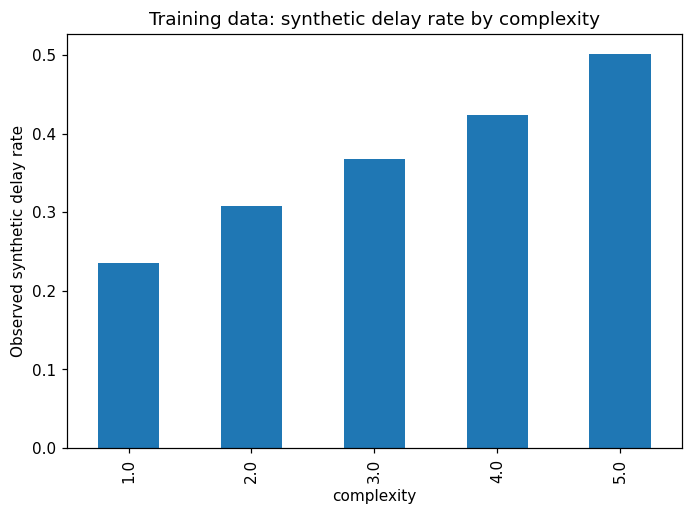

In [5]:
summary = train_df.groupby("complexity").agg(packages=(TARGET,"size"), delay_rate=(TARGET,"mean"))
print(summary.round(3).to_string())
high_risk_inputs = train_df.loc[train_df["supply_risk"] > 0.75, ["supply_risk","forecast_rain_days",TARGET]]
print("High supply-risk sample:")
print(high_risk_inputs.head().round(2).to_string(index=False))
summary["delay_rate"].plot.bar(title="Training data: synthetic delay rate by complexity")
plt.ylabel("Observed synthetic delay rate")
plt.tight_layout()

## 7. Training-only preprocessing and model / Подготовка и обучение
Fit the median imputer exclusively on training records inside a Pipeline. Fixed model settings; no test-set tuning.

In [6]:
model = Pipeline([("imputer", SimpleImputer(strategy="median")),
                  ("forest", RandomForestClassifier(n_estimators=160, min_samples_leaf=14, random_state=23, n_jobs=1))])
baseline = DummyClassifier(strategy="prior")
model.fit(X_train, y_train)
baseline.fit(X_train, y_train)
print("Training complete; fitted features:", FEATURES)

Training complete; fitted features: ['planned_days', 'crew_size', 'supply_risk', 'forecast_rain_days', 'complexity']


## 8. Held-out evaluation / Проверка на отложенных данных
Compare with a simple baseline. Synthetic test performance does not establish real-site accuracy.

              model  average_precision  Brier_score
      Random forest             0.5367       0.2039
Training prevalence             0.3417       0.2256
ROC AUC: 0.6912
Precision at 0.50: 0.5748
Recall at 0.50: 0.4451


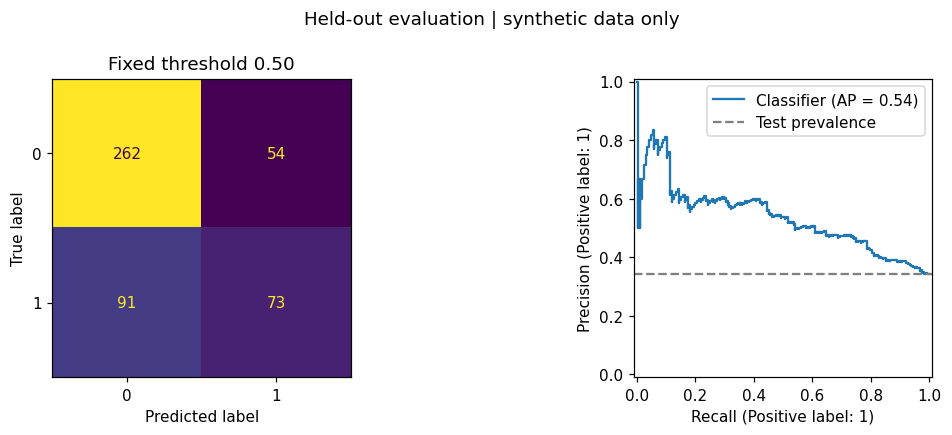

In [7]:
probability = model.predict_proba(X_test)[:,1]
baseline_probability = baseline.predict_proba(X_test)[:,1]
prediction = probability >= 0.50  # Fixed before viewing test outcomes.
comparison = pd.DataFrame({"model":["Random forest","Training prevalence"],
    "average_precision":[average_precision_score(y_test,probability),
                         average_precision_score(y_test,baseline_probability)],
    "Brier_score":[brier_score_loss(y_test,probability),
                   brier_score_loss(y_test,baseline_probability)]})
print(comparison.round(4).to_string(index=False))
print("ROC AUC:", round(roc_auc_score(y_test,probability),4))
print("Precision at 0.50:", round(precision_score(y_test,prediction,zero_division=0),4))
print("Recall at 0.50:", round(recall_score(y_test,prediction,zero_division=0),4))
assert np.isfinite(probability).all()
fig, axes = plt.subplots(1,2,figsize=(11,4))
ConfusionMatrixDisplay.from_predictions(y_test,prediction,ax=axes[0],colorbar=False)
axes[0].set_title("Fixed threshold 0.50")
PrecisionRecallDisplay.from_predictions(y_test,probability,ax=axes[1])
axes[1].axhline(y_test.mean(),ls="--",color="grey",label="Test prevalence")
axes[1].legend()
fig.suptitle("Held-out evaluation | synthetic data only")
plt.tight_layout()

## 9. Model interpretation / Интерпретация
Permutation importance measures score deterioration after shuffling an input. It is not evidence of causality; correlated features can share importance.

           feature  importance    std
       supply_risk      0.0961 0.0301
        complexity      0.0754 0.0080
forecast_rain_days      0.0328 0.0238
         crew_size      0.0267 0.0149
      planned_days      0.0071 0.0039


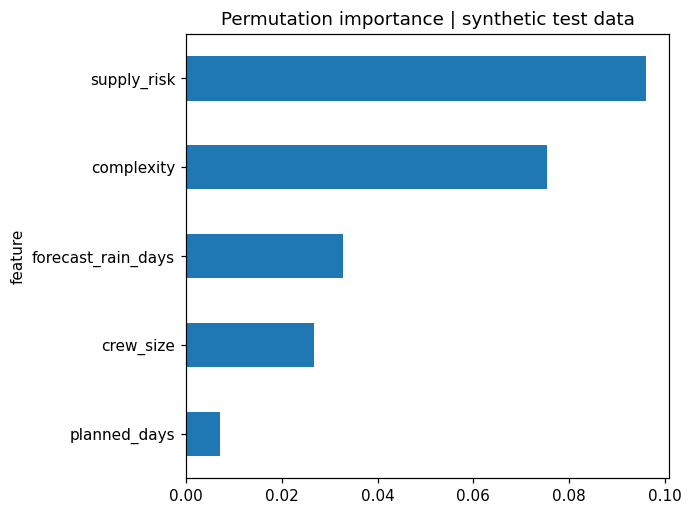

In [8]:
importance = permutation_importance(model, X_test, y_test,
    scoring='average_precision', n_repeats=5, random_state=29)
importance_df = pd.DataFrame({"feature": FEATURES,
    "importance": importance.importances_mean,
    "std": importance.importances_std}).sort_values("importance", ascending=False)
print(importance_df.round(4).to_string(index=False))
importance_df.sort_values("importance").plot.barh(x="feature", y="importance", legend=False)
plt.title("Permutation importance | synthetic test data")
plt.tight_layout()

## 10. Conclusions and next steps / Выводы
- The workflow demonstrates Pandas preparation, scikit-learn preprocessing, training and baseline comparison.
- All findings depend on the explicitly imposed synthetic mechanism; no measured business savings are claimed.
- This single group holdout is not forward-time validation. A real pilot needs approved historical records, availability checks, temporal evaluation, calibration review and monitoring.
- Engineers and planners own operational decisions. The model cannot operate or stop equipment.

Практика: объясните целевую переменную, зачем отделять проверочные данные и чем модель лучше базового варианта. Затем измените один параметр и сравните результаты, не выбирая лучший вариант по тестовой выборке.
